# Prévision horaire de consommation — premières étapes
Notebook complété à partir de `Code.ipynb`, du CSV fourni et du plan d'étude.

Les étapes 1 à 4 sont préparées : cadre provisoire, audit, exploration, variables, découpage et référence naïve. Les modèles ne sont pas encore entraînés.

**Utilisation :** placer le CSV à côté du notebook, ou modifier `DATA_PATH` dans la cellule de chargement. Exécuter les cellules dans l'ordre. Dépendances : pandas, numpy, matplotlib.

## 1. Cadre de prévision provisoire
- On prévoit la consommation de l'heure **s**, à la fin de l'heure **s − 1 h**, en supposant les mesures de cette dernière disponibles sans délai. C'est une prévision glissante à une heure, pas une prévision des 24 heures d'un coup.
- Le modèle commun sera une régression sur des données de panel : une ligne par poste et heure cible, une seule variable dépendante et l'identifiant du poste encodé. Les modèles individuels utilisent les mêmes variables, sauf cet identifiant.
- Une heure est dite critique si la consommation observée dépasse le **95e percentile du poste calculé sur 2022**. Ce seuil provisoire reste fixe en validation et en test. C'est une classification pour l'évaluation a posteriori, pas une variable explicative connue à l'avance.
- Apprentissage : 2022 ; validation : 2023 ; test : janvier–juin 2024, selon **l'heure de la cible**. Après sélection, réentraînement sur 2022–2023.
- Référence : consommation à la même heure locale la veille, soit y(s − 24 h).
- Unités de consommation et convention des heures locales à confirmer auprès de la source.

Le plan cite cinq familles de modèles ; avec deux stratégies, cela donne **dix configurations**, auxquelles s'ajoute la référence naïve. La mention « six configurations » doit donc être actualisée.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True})

DATA_PATH = Path('C:/Users/haida/Documents/HEC Cours/Maitrise/ML/Projet/Data/data_AD.csv')  # À modifier si nécessaire
candidates = [DATA_PATH, Path('data_AD.csv'), Path('upload') / DATA_PATH,
              Path('../upload') / DATA_PATH]
DATA_PATH = next((p for p in candidates if p.exists()), DATA_PATH)
# Préserve le texte "None" : ici il désigne l'absence de défi.
data = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[''])
print(data.head())
print('\nColonnes :', data.columns.tolist())

   Unnamed: 0 substation        date  hour      timestamp_local  connected_clients  total_energy_consumed  average_temperature_setpoint  \
0           0          A  2022-01-01     0  2022-01-01T00:00:00                 17              60.931664                     16.954739   
1           1          A  2022-01-01     1  2022-01-01T01:00:00                 17              59.117008                     16.823880   
2           2          A  2022-01-01     2  2022-01-01T02:00:00                 17              54.922043                     16.791683   
3           3          A  2022-01-01     3  2022-01-01T03:00:00                 17              52.323657                     16.576247   
4           4          A  2022-01-01     4  2022-01-01T04:00:00                 17              55.789580                     16.567725   

   average_inside_temperature  connected_smart_tstats  average_solar_radiance  average_relative_humidity  average_snow_precipitation  \
0                   17.501921

## 2. Audit et préparation
La colonne sans nom est un ancien index exporté. Les horodatages sont locaux et sans décalage UTC : les changements d'heure ne peuvent pas être reconstruits avec certitude. On utilise donc une grille d'heures locales et des correspondances exactes. Les heures absentes restent manquantes ; aucune interpolation ni remplissage avec des valeurs futures.

**Attention :** une fréquence horaire déclarée ne garantit pas que chaque heure soit présente. `shift(24)` ne représente 24 heures qu'après reconstruction d'une grille régulière.

In [2]:
data = data.drop(columns=[c for c in data if c.startswith('Unnamed:')]).copy()
data['timestamp_local'] = pd.to_datetime(data['timestamp_local'], errors='raise')
data = data.sort_values(['substation', 'timestamp_local']).reset_index(drop=True)
assert data['timestamp_local'].dt.hour.eq(data['hour']).all()
assert data['timestamp_local'].dt.normalize().eq(pd.to_datetime(data['date'])).all()
print('Dimensions :', data.shape)
print('\nValeurs manquantes :\n', data.isna().sum())
print('\nTypes de défi :\n', data['challenge_type'].value_counts(dropna=False))
print('\nDoublons poste–heure :', data.duplicated(['substation', 'timestamp_local']).sum())
assert not data.duplicated(['substation', 'timestamp_local']).any(), 'Examiner les doublons avant de poursuivre.'

coverage = []
missing_tables = []
for poste, g in data.groupby('substation'):
    expected = pd.date_range(g.timestamp_local.min(), g.timestamp_local.max(), freq='h')
    missing = expected.difference(g.timestamp_local)
    coverage.append({'poste': poste, 'début': expected.min(), 'fin': expected.max(),
                     'observées': len(g), 'attendues_grille_locale': len(expected), 'absentes': len(missing)})
    missing_tables.append(pd.DataFrame({'substation': poste, 'timestamp_local': missing}))
coverage = pd.DataFrame(coverage)
missing_hours = pd.concat(missing_tables, ignore_index=True)
print('\nCouverture :\n', coverage.to_string(index=False))
print('\nHeures locales absentes par poste :\n', pd.crosstab(missing_hours.substation, missing_hours.timestamp_local.dt.hour))
print('\nConsommations les plus élevées (à vérifier, pas supprimées) :\n',
      data.nlargest(10, 'total_energy_consumed')[['substation', 'timestamp_local', 'total_energy_consumed']].to_string(index=False))
assert data['total_energy_consumed'].ge(0).all()

# Une grille complète par poste ; les lignes ajoutées n'ont aucune mesure inventée.
parts = []
for poste, g in data.groupby('substation'):
    g = g.set_index('timestamp_local')
    full_index = pd.date_range(g.index.min(), g.index.max(), freq='h', name='timestamp_local')
    expanded = g.reindex(full_index)
    expanded['observed_row'] = expanded.index.isin(g.index)
    expanded['substation'] = poste
    parts.append(expanded.reset_index())
grid = pd.concat(parts, ignore_index=True).sort_values(['substation', 'timestamp_local'])
print('\nGrille reconstruite :', grid.shape)

Dimensions : (64605, 29)

Valeurs manquantes :
 substation                      0
date                            0
hour                            0
timestamp_local                 0
connected_clients               0
total_energy_consumed           0
average_temperature_setpoint    0
average_inside_temperature      0
connected_smart_tstats          0
average_solar_radiance          0
average_relative_humidity       0
average_snow_precipitation      0
average_wind_speed              0
average_outside_temperature     0
challenge_type                  0
challenge_flag                  0
pre_post_challenge_flag         0
month                           0
day                             0
day_of_week                     0
month_cos                       0
month_sin                       0
day_of_week_cos                 0
day_of_week_sin                 0
is_weekend                      0
is_holiday                      0
weekend_holiday                 0
hour_sin                        0


### Constats de l'audit du fichier fourni
Repérer les heures absentes et ajouter leur emplacement
- 64 605 observations : 21 535 par poste, du 1er janvier 2022 au 30 juin 2024 inclus.
- Aucun doublon poste–heure ; aucun champ vide dans le CSV original. `None` dans `challenge_type` signifie « aucun défi » et ne doit pas entraîner la suppression de ces lignes.
- 353 heures absentes par poste dans la grille locale : **350 à minuit et trois à 2 h**. Les trois heures à 2 h correspondent aux dates de passage à l'heure d'été ; cela ne suffit pas à expliquer les absences à minuit. Vérifier la source et sa gestion du fuseau horaire avant une étude finale.
- Plusieurs valeurs extrêmes, notamment 32 240,17 au poste A le 10 août 2022 à 13 h. Ce sont des points à vérifier, pas des erreurs établies. Ils sont conservés ici. Aucune unité n'est supposée.
- Le nombre de clients varie au cours du temps : il peut contribuer à expliquer une évolution de la consommation totale.

### Exploration sur 2022 uniquement
Les graphiques de développement sont limités à l'entraînement afin de garder le test réservé à l'évaluation finale. Les moyennes conservent les valeurs extrêmes ; les médianes aident à visualiser le profil habituel sans les supprimer.

| Graphique | Ce qu’il permet d’observer |
|---|---|
| Moyenne journalière | L’évolution de la consommation au fil de l’année |
| Profil horaire médian | Les heures habituellement les plus consommatrices |
| Profil hebdomadaire médian | Les différences entre les jours de la semaine |
| Profil mensuel médian | Les variations saisonnières |

           total_energy_consumed                           connected_clients                   
                             min  median    mean       max               min median   mean  max
substation                                                                                     
A                          11.10   63.37   93.39  32240.17                17   28.0  29.37   46
B                           7.45   46.97   66.68   8890.27                 9   19.0  18.70   37
C                          25.63  147.46  204.20  11804.20                35   65.0  66.28  100


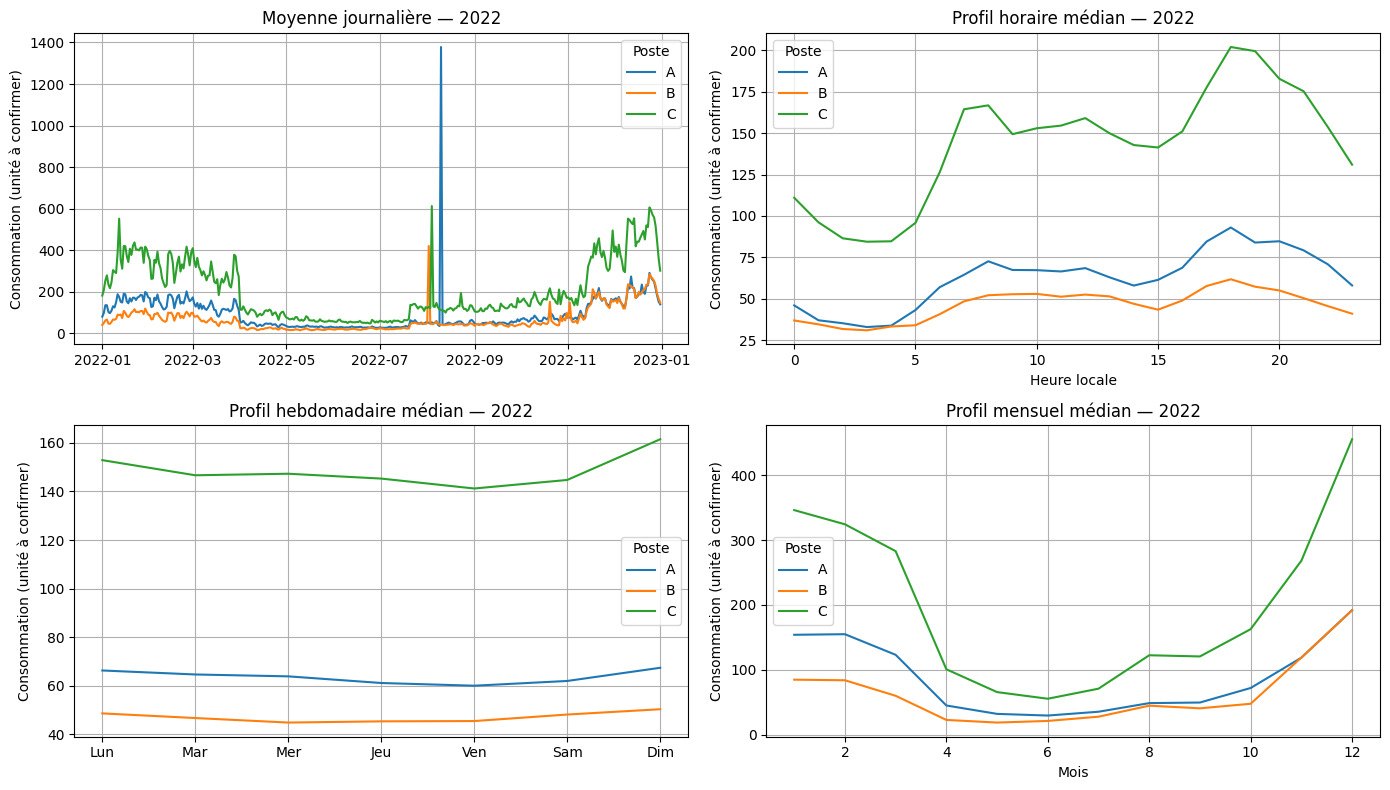

In [3]:
eda = data.loc[data.timestamp_local.dt.year.eq(2022)].copy()
print(eda.groupby('substation')[['total_energy_consumed', 'connected_clients']].agg(['min', 'median', 'mean', 'max']).round(2))
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for poste, g in eda.groupby('substation'):
    daily = g.set_index('timestamp_local')['total_energy_consumed'].resample('D').mean()
    axes[0, 0].plot(daily.index, daily.values, label=poste)
    axes[0, 1].plot(g.groupby(g.timestamp_local.dt.hour).total_energy_consumed.median(), label=poste)
    axes[1, 0].plot(g.groupby(g.timestamp_local.dt.dayofweek).total_energy_consumed.median(), label=poste)
    axes[1, 1].plot(g.groupby(g.timestamp_local.dt.month).total_energy_consumed.median(), label=poste)
for ax, title in zip(axes.flat, ['Moyenne journalière — 2022', 'Profil horaire médian — 2022',
                                  'Profil hebdomadaire médian — 2022', 'Profil mensuel médian — 2022']):
    ax.set_title(title)
    ax.set_ylabel('Consommation (unité à confirmer)')
    ax.legend(title='Poste')
axes[0, 1].set_xlabel('Heure locale')
axes[1, 0].set_xticks(range(7), ['Lun', 'Mar', 'Mer', 'Jeu', 'Ven', 'Sam', 'Dim'])
axes[1, 1].set_xlabel('Mois')
fig.tight_layout()
plt.show()

## 3. Variables explicatives, sans information future
Chaque ligne est indexée par **l'heure à prédire s**. `load_lag_1h` contient y(s−1 h), déjà connu sous notre hypothèse de disponibilité ; `load_lag_24h` contient y(s−24 h).

Les moyennes historiques excluent la cible. La météo et le nombre de clients sont décalés d'une heure : aucune météo réellement observée à l'heure future n'entre dans les variables. Pour un futur modèle à 24 h, il faudra redéfinir ces variables ou utiliser des prévisions météo réellement disponibles à l'origine.

Le calendrier de l'heure cible est connu à l'avance. Les indicateurs de défi contemporains servent uniquement à une analyse ultérieure, car leur disponibilité à l'origine n'est pas documentée. Les températures intérieures et consignes sont laissées de côté dans cette première base.

In [4]:
TARGET = 'total_energy_consumed'
model_data = grid[['substation', 'timestamp_local', 'observed_row', TARGET]].copy()
groups = grid.groupby('substation', sort=False)
load_features = []
for lag in [1, 2, 24, 48, 168]:
    col = f'load_lag_{lag}h'
    model_data[col] = groups[TARGET].shift(lag)
    load_features.append(col)
for window in [24, 168]:
    col = f'load_mean_{window}h'
    model_data[col] = groups[TARGET].transform(lambda x: x.shift(1).rolling(window, min_periods=window).mean())
    load_features.append(col)
    # Utile pour voir combien de moyennes complètes sont perdues à cause des trous.
    model_data[f'load_count_{window}h'] = groups[TARGET].transform(lambda x: x.shift(1).rolling(window, min_periods=1).count())

observed_features = ['connected_clients', 'average_outside_temperature',
                     'average_relative_humidity', 'average_wind_speed',
                     'average_solar_radiance', 'average_snow_precipitation']
weather_features = []
for col in observed_features:
    name = col + '_lag_1h'
    model_data[name] = groups[col].shift(1)
    weather_features.append(name)

s = model_data['timestamp_local']
model_data['forecast_origin'] = s - pd.Timedelta(hours=1)
model_data['hour_sin'] = np.sin(2 * np.pi * s.dt.hour / 24)
model_data['hour_cos'] = np.cos(2 * np.pi * s.dt.hour / 24)
model_data['weekday_sin'] = np.sin(2 * np.pi * s.dt.dayofweek / 7)
model_data['weekday_cos'] = np.cos(2 * np.pi * s.dt.dayofweek / 7)
model_data['month_sin'] = np.sin(2 * np.pi * (s.dt.month - 1) / 12)
model_data['month_cos'] = np.cos(2 * np.pi * (s.dt.month - 1) / 12)
model_data['is_weekend'] = (s.dt.dayofweek >= 5).astype(int)
# Le calendrier férié fourni est connu à l'avance ; pas d'inférence depuis la cible.
model_data['is_holiday'] = grid['is_holiday'].astype(float)
calendar_features = ['hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos',
                     'month_sin', 'month_cos', 'is_weekend', 'is_holiday']
FEATURES = load_features + weather_features + calendar_features
model_data['naive_24h'] = model_data['load_lag_24h']

# Exemple d'alignement, au sein d'un seul poste.
print(model_data.loc[model_data.substation.eq('A'),
      ['timestamp_local', 'forecast_origin', TARGET, 'load_lag_1h', 'load_lag_24h', 'naive_24h']].iloc[24:30].to_string(index=False))
print('\nVariables :', FEATURES)
assert TARGET not in FEATURES
assert (model_data.forecast_origin < model_data.timestamp_local).all()
# Contrôle indépendant du retard 24 h, par correspondance sur les horodatages.
lookup = data.set_index(['substation', 'timestamp_local'])[TARGET]
keys = pd.MultiIndex.from_arrays([model_data.substation, model_data.timestamp_local - pd.Timedelta(hours=24)])
expected = lookup.reindex(keys).to_numpy()
assert np.allclose(model_data.naive_24h.to_numpy(), expected, equal_nan=True)

    timestamp_local     forecast_origin  total_energy_consumed  load_lag_1h  load_lag_24h  naive_24h
2022-01-02 00:00:00 2022-01-01 23:00:00              59.275862    64.413417     60.931664  60.931664
2022-01-02 01:00:00 2022-01-02 00:00:00              55.071473    59.275862     59.117008  59.117008
2022-01-02 02:00:00 2022-01-02 01:00:00              48.217818    55.071473     54.922043  54.922043
2022-01-02 03:00:00 2022-01-02 02:00:00              55.665191    48.217818     52.323657  52.323657
2022-01-02 04:00:00 2022-01-02 03:00:00              56.880812    55.665191     55.789580  55.789580
2022-01-02 05:00:00 2022-01-02 04:00:00              77.228509    56.880812     67.415305  67.415305

Variables : ['load_lag_1h', 'load_lag_2h', 'load_lag_24h', 'load_lag_48h', 'load_lag_168h', 'load_mean_24h', 'load_mean_168h', 'connected_clients_lag_1h', 'average_outside_temperature_lag_1h', 'average_relative_humidity_lag_1h', 'average_wind_speed_lag_1h', 'average_solar_radiance_lag_1h', '

## 4. Découpage et prévision naïve
Les lignes sans cible, sans consommation de l'heure précédente ou sans référence à 24 h sont exclues de l'échantillon de comparaison commun. On ne supprime pas les lignes à cause des autres variables manquantes : les modèles devront utiliser une imputation ajustée sur l'entraînement, dans un pipeline. Les moyennes à 168 h seront fréquemment manquantes tant que les trous à minuit ne sont pas expliqués.

Les vrais historiques de validation/test peuvent servir aux prévisions suivantes : c'est le protocole glissant à une heure annoncé. Les paramètres du modèle restent fixes pendant chaque évaluation.

Les indicateurs critiques sont construits avec la consommation réelle, uniquement pour l'évaluation ; **ils ne figurent pas dans `FEATURES`**.

In [5]:
model_data['split'] = np.select(
    [s.dt.year.eq(2022), s.dt.year.eq(2023), (s >= '2024-01-01') & (s < '2024-07-01')],
    ['train', 'validation', 'test'], default='hors_periode')
thresholds = data.loc[data.timestamp_local.dt.year.eq(2022)].groupby('substation')[TARGET].quantile(0.95)
model_data['critical_threshold'] = model_data.substation.map(thresholds)
model_data['is_critical'] = (model_data[TARGET] > model_data.critical_threshold).where(model_data[TARGET].notna())
print('Seuils critiques (95e percentile de 2022) :\n', thresholds.round(3))

eligible = model_data['observed_row'] & model_data[[TARGET, 'load_lag_1h', 'naive_24h']].notna().all(axis=1)
samples = model_data.loc[eligible & model_data.split.ne('hors_periode')].copy()
print('\nEffectifs conservés :\n', pd.crosstab(samples.split, samples.substation))
print('\nLignes exclues par période :\n', model_data.loc[~eligible].groupby('split').size())
train = samples.loc[samples.split.eq('train')].copy()
validation = samples.loc[samples.split.eq('validation')].copy()
test = samples.loc[samples.split.eq('test')].copy()
train_final = pd.concat([train, validation], ignore_index=True)
assert train.timestamp_local.max() < validation.timestamp_local.min()
assert validation.timestamp_local.max() < test.timestamp_local.min()
print('\nTaux de valeurs manquantes des variables sur 2022 (%) :\n',
      train[FEATURES].isna().mean().mul(100).round(2).sort_values(ascending=False))
print('\nVariables disponibles pour la suite : train, validation, test, train_final, FEATURES, TARGET')

Seuils critiques (95e percentile de 2022) :
 substation
A    218.065
B    192.784
C    493.669
Name: total_energy_consumed, dtype: float64

Effectifs conservés :
 substation     A     B     C
split                       
test        4141  4141  4141
train       8733  8733  8733
validation  8280  8280  8280

Lignes exclues par période :
 split
test           681
train           81
validation    1440
dtype: int64

Taux de valeurs manquantes des variables sur 2022 (%) :
 load_mean_168h                        3.55
load_lag_168h                         1.66
load_lag_48h                          0.29
load_mean_24h                         0.25
load_lag_2h                           0.01
load_lag_24h                          0.00
load_lag_1h                           0.00
connected_clients_lag_1h              0.00
average_outside_temperature_lag_1h    0.00
average_relative_humidity_lag_1h      0.00
average_wind_speed_lag_1h             0.00
average_solar_radiance_lag_1h         0.00
average_sno

In [6]:
def evaluate_naive(frame):
    rows = []
    for poste, group in frame.groupby('substation'):
        for regime, mask in [('Toutes', pd.Series(True, index=group.index)),
                             ('Critiques', group.is_critical.eq(True)),
                             ('Ordinaires', group.is_critical.eq(False))]:
            g = group.loc[mask]
            errors = g[TARGET] - g.naive_24h
            rows.append({'poste': poste, 'période': regime, 'n': len(g),
                         'MAE': errors.abs().mean(), 'RMSE': np.sqrt(errors.pow(2).mean())})
    return pd.DataFrame(rows)

# Première référence de développement : validation seulement.
validation_naive = evaluate_naive(validation)
print(validation_naive.round(3).to_string(index=False))
# L'agrégation globale utilise toutes les erreurs individuelles, dans l'unité de consommation.
errors = validation[TARGET] - validation.naive_24h
print('\nValidation globale : MAE =', round(errors.abs().mean(), 3),
      '; RMSE =', round(np.sqrt(errors.pow(2).mean()), 3))

# Laisser False pendant la conception et le réglage des modèles.
EVALUATE_FINAL_TEST = False
if EVALUATE_FINAL_TEST:
    print('\nTest final :\n', evaluate_naive(test).round(3).to_string(index=False))

poste    période    n     MAE    RMSE
    A     Toutes 8280  27.972  53.342
    A  Critiques 1540  56.362 102.846
    A Ordinaires 6740  21.485  32.844
    B     Toutes 8280  23.396  41.916
    B  Critiques 1631  48.249  78.549
    B Ordinaires 6649  17.300  25.970
    C     Toutes 8280  52.255  90.454
    C  Critiques 1369 114.806 167.551
    C Ordinaires 6911  39.864  65.128

Validation globale : MAE = 34.541 ; RMSE = 65.28


## Suite du travail
1. Confirmer l'horizon à une heure, les unités, la disponibilité des mesures et la convention des heures locales ; demander pourquoi 350 minuits sont absents par poste.
2. Vérifier les valeurs extrêmes auprès de la source. Ne pas appliquer une correction fondée sur le test ; documenter toute correction et prévoir, si nécessaire, une analyse de sensibilité.
3. Construire des pipelines : imputation apprise sur 2022, standardisation pour les modèles qui la nécessitent, encodage de `substation` pour le modèle commun. Les colonnes entièrement manquantes sur l'entraînement devront être exclues selon une règle fondée sur l'entraînement.
4. Estimer d'abord la régression linéaire et Elastic Net, par poste puis en commun ; utiliser exactement les mêmes lignes d'évaluation que la référence. Ajouter ensuite les modèles non linéaires.
5. Choisir les hyperparamètres sur 2023. Réajuster tout le pipeline sur 2022–2023 avant d'évaluer une seule fois le test. Conserver les seuils critiques de 2022 pour cette première définition stable.

La référence et les résultats restent **provisoires** tant que les horodatages et les valeurs extrêmes ne sont pas clarifiés. L'agrégation globale favorise les postes dont les erreurs absolues sont les plus élevées ; présenter aussi les résultats par poste et les gains relatifs par rapport à la référence.